In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import nbimporter
from preprocessing_feature_selection import get_breast_cancer

# to get standardized X features function parameter => std='std'
X_train, X_test, y_train, y_test = get_breast_cancer()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (455, 30)
Testing data: (114, 30)


In [3]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [4]:
from sklearn.ensemble import RandomForestClassifier

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=cv,
    scoring="recall",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [None, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [100, 200, ...]}"
,scoring,'recall'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,300


In [5]:
print("Best parameters:", grid_search.best_params_)
print("Best CV recall:", grid_search.best_score_)

Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 300}
Best CV recall: 0.9470588235294117


# Model Interpretation

Model interpretation helps us understand **why a machine learning model makes particular predictions** and which input features influence its decisions.

Instead of only evaluating model performance, interpretation provides insights into how the model uses the dataset to distinguish between benign and malignant cases.

There are three important techniques used in this project.

## A. Feature Importance

**Definition:**

Feature importance identifies which input variables contribute most to a model's predictions.

In Random Forest, feature importance is calculated using the reduction in impurity (typically Gini impurity) across decision tree splits.

**Purpose:**
- Identify the most influential features.
- Understand which variables contribute most to classification.
- Rank features based on their importance.
- Help identify potentially unnecessary features.

**Interpretation:**

Features with higher importance scores contribute more to the model's decision-making process.

**Limitation:**

Random Forest feature importance does not explain whether a feature increases or decreases the probability of malignancy. It also can be biased toward certain feature types and correlated variables.

In [7]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

rf_model.fit(X_train, y_train)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [8]:
# Extract feature importance
# Use the feature_importances_ attribute to retrieve importance scores.

import pandas as pd

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

,Feature,Importance
22,perimeter3,0.143121
23,area3,0.142449
27,concave_points3,0.112978
7,concave_points1,0.088663
20,radius3,0.082649
0,radius1,0.061043
2,perimeter1,0.052928
3,area1,0.043820
6,concavity1,0.039761
13,area2,0.032237


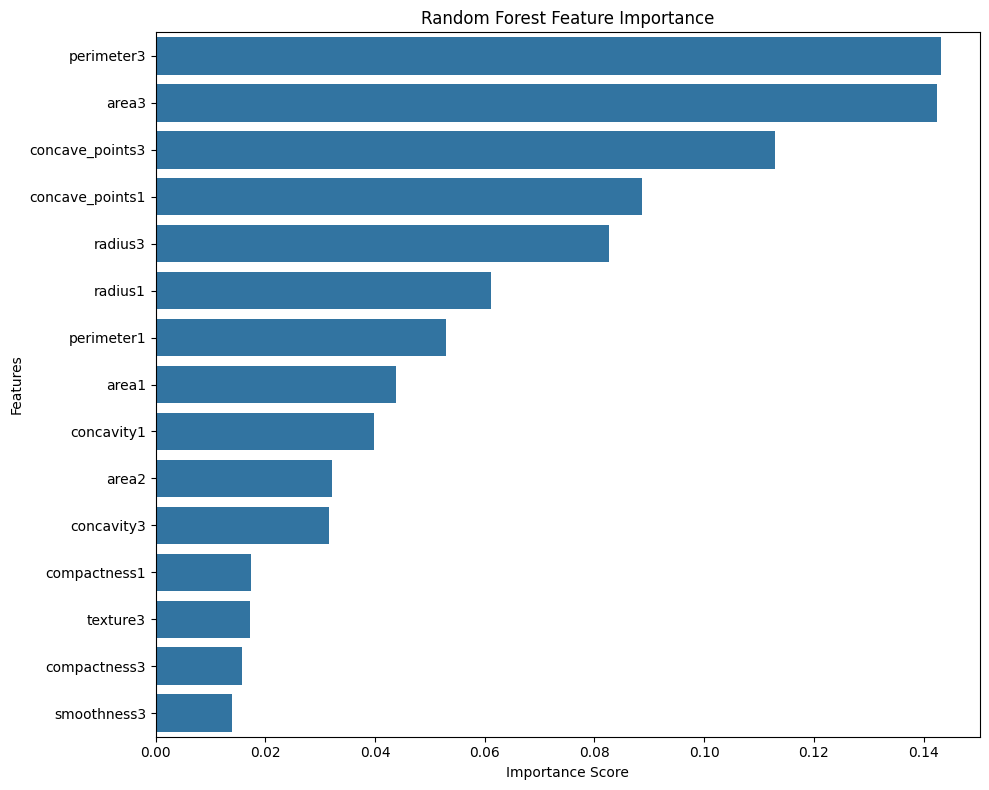

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.barplot(
    data=importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [13]:
print("Top 10 Important Features:")

print(
    importance.head(10).to_string(index=False)
)

Top 10 Important Features:
        Feature  Importance
     perimeter3    0.143121
          area3    0.142449
concave_points3    0.112978
concave_points1    0.088663
        radius3    0.082649
        radius1    0.061043
     perimeter1    0.052928
          area1    0.043820
     concavity1    0.039761
          area2    0.032237


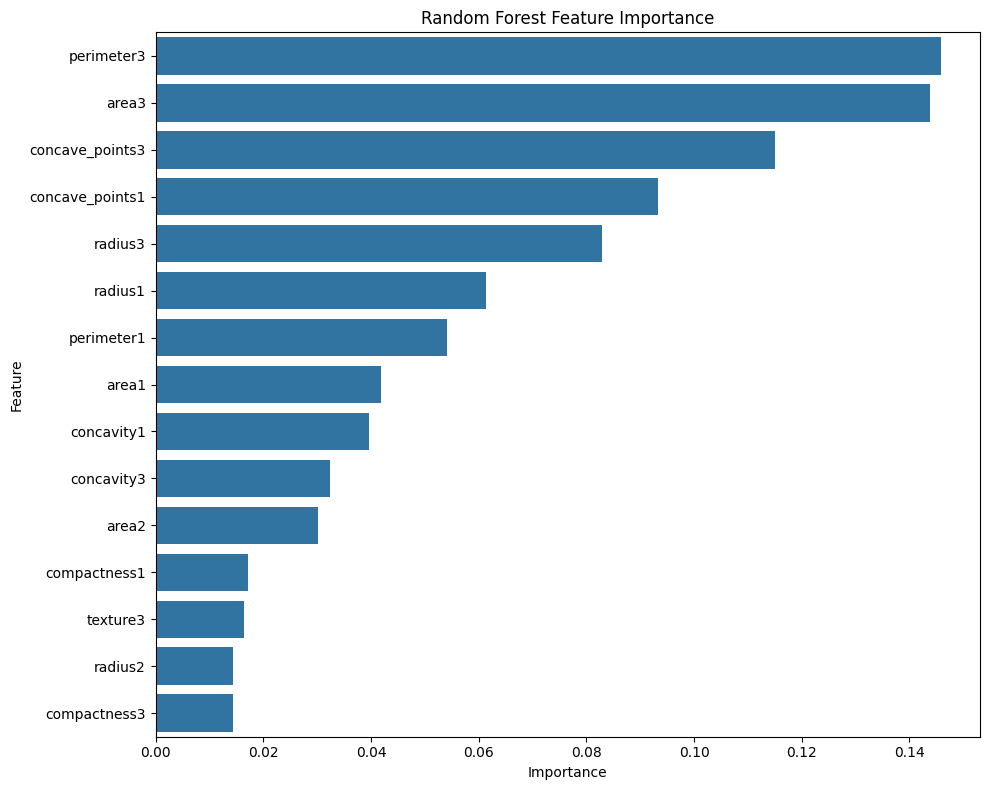

In [14]:
best_model = grid_search.best_estimator_

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

## B. Permutation Importance

**Definition:**

Permutation importance measures how much a model's performance decreases when the values of an individual feature are randomly shuffled.

The model's performance is evaluated before and after shuffling a feature.

**Working process:**

1. Train the machine learning model.
2. Calculate its baseline performance.
3. Randomly shuffle one feature's values.
4. Calculate the model's performance again.
5. Measure the difference between baseline and shuffled performance.
6. Repeat the process multiple times.
7. Rank features based on their average performance decrease.

**Formula:**

Permutation Importance = Baseline Score − Shuffled Score

**Purpose:**
- Identify features that significantly affect model performance.
- Understand the contribution of individual features.
- Compare the importance of different variables.
- Support feature selection.

**Interpretation:**

- Higher importance: Shuffling the feature significantly reduces model performance.
- Near-zero importance: Shuffling the feature has little effect.
- Negative importance: Shuffling the feature improves model performance, suggesting it may be noisy or unhelpful.

**Important:** Permutation importance depends on the selected evaluation metric. In this project, recall is used to measure the importance of features for identifying malignant cases.

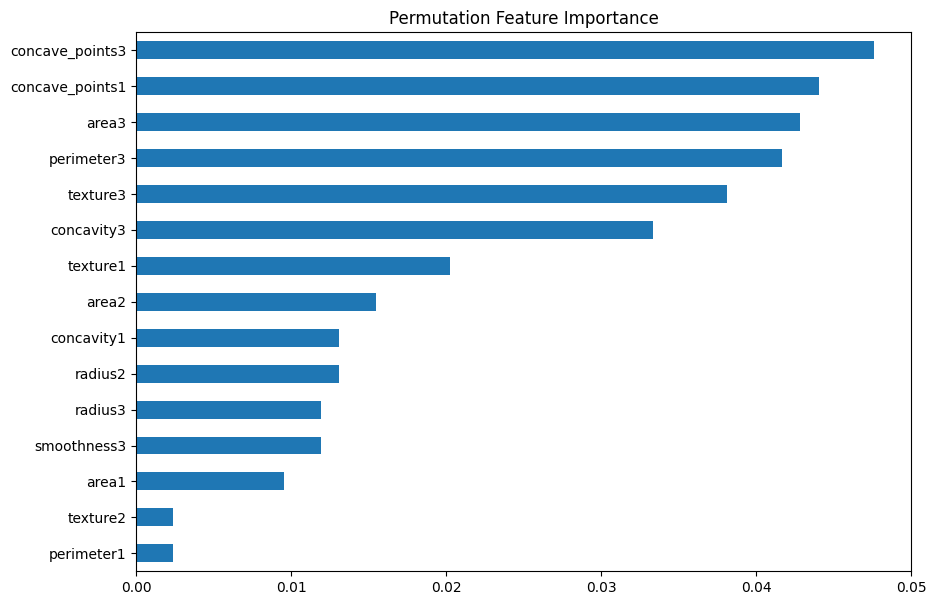

In [15]:
from sklearn.inspection import permutation_importance

best_model = grid_search.best_estimator_

perm = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="recall"
)

importance = pd.Series(
    perm.importances_mean,
    index=X_test.columns
).sort_values(ascending=False)

importance.head(15).plot(
    kind="barh",
    figsize=(10, 7)
)

plt.gca().invert_yaxis()
plt.title("Permutation Feature Importance")
plt.show()

## C. SHAP (SHapley Additive exPlanations)

**Definition:**

SHAP is a model explainability technique based on game theory. It explains how much each input feature contributes to an individual prediction.

It calculates feature contributions by evaluating how predictions change when different combinations of features are considered.

**Purpose:**
- Explain individual model predictions.
- Identify influential features across the dataset.
- Understand whether a feature pushes a prediction toward benign or malignant.
- Improve model transparency and interpretability.

### Important SHAP visualizations

**1. SHAP Summary (Beeswarm) Plot**

Shows the influence and distribution of feature contributions across multiple samples.

Interpretation:
- Features are ranked by their overall SHAP impact.
- Positive SHAP values push predictions toward the explained class.
- Negative SHAP values push predictions away from the explained class.
- Red generally represents higher feature values.
- Blue generally represents lower feature values.

**2. SHAP Bar Plot**

Displays the average absolute SHAP value for each feature.

It helps identify which features have the greatest overall influence on predictions.

**3. SHAP Waterfall Plot**

Explains an individual prediction by showing how each feature moves the model output from its baseline value to the final prediction.

**4. SHAP Dependence Plot**

Shows the relationship between an individual feature's values and its SHAP contributions.

It helps identify how changes in feature values influence model predictions.

### Important considerations

- SHAP output formats depend on the model and SHAP version.
- Binary classification models may return separate SHAP values for each class.
- Select the malignant class when analyzing malignant-class predictions.
- TreeExplainer is suitable for tree-based models such as Random Forest and Gradient Boosting.

In [18]:
import shap

explainer = shap.TreeExplainer(best_model)
shap_values = explainer(X_test)

print("SHAP shape:", shap_values.values.shape)
print("Feature shape:", X_test.shape)

SHAP shape: (114, 30, 2)
Feature shape: (114, 30)


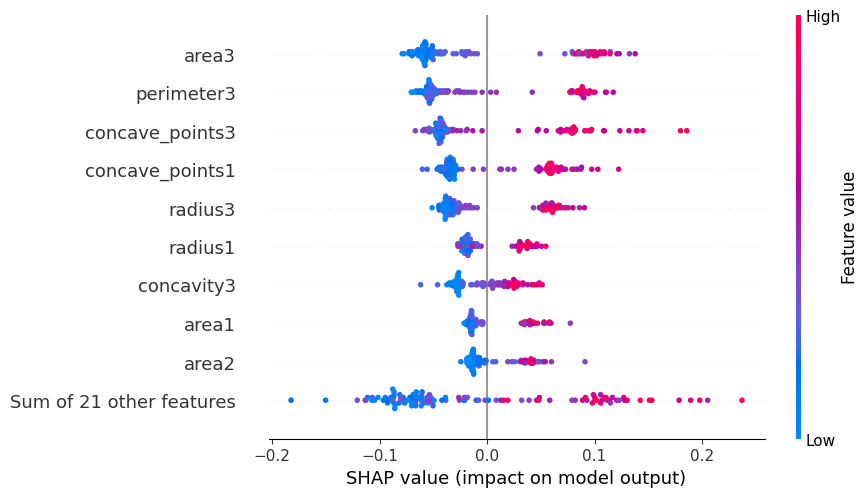

In [19]:
# Select the malignant class
# Since your primary objective is identifying malignant cases, select class 1.
    
# Select malignant class (class 1)
shap_values_malignant = shap_values[:, :, 1]

# Generate SHAP beeswarm plot
shap.plots.beeswarm(shap_values_malignant)

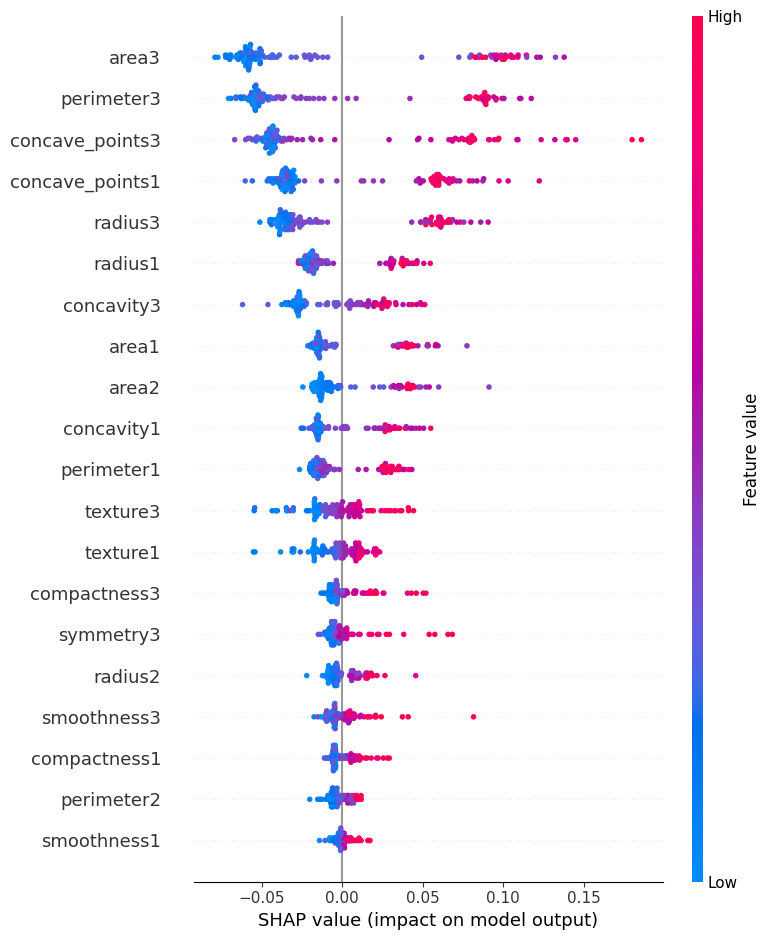

In [20]:
# Generate additional SHAP visualizations
# Once you have selected the malignant class, you can generate these plots.

# A. SHAP Summary Plot
shap.summary_plot(
    shap_values_malignant.values,
    X_test
)

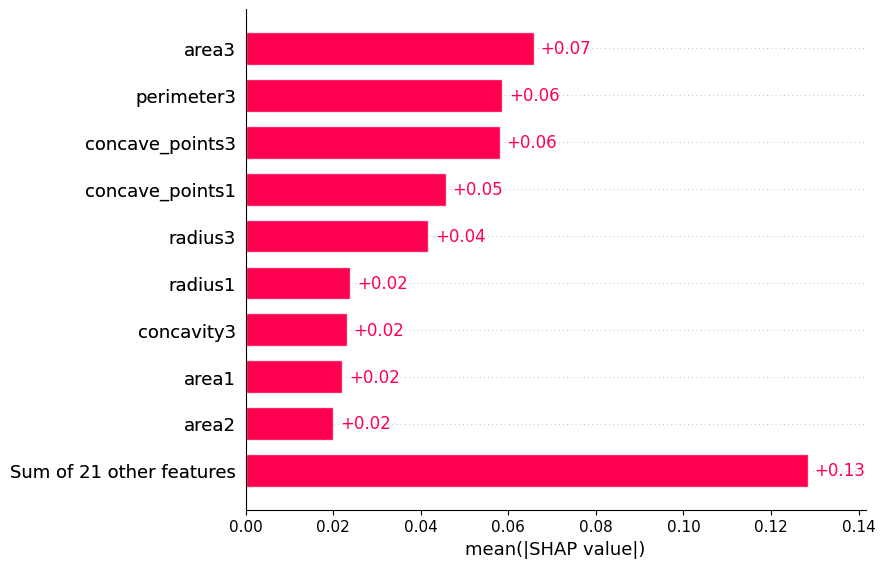

In [21]:
# B. SHAP Feature Importance

shap.plots.bar(shap_values_malignant)

## Comparison of Model Interpretation Techniques

| Technique | What It Explains | Main Purpose |
|---|---|---|
| Feature Importance | Overall feature contribution | Identify influential variables |
| Permutation Importance | Impact of a feature on model performance | Evaluate feature usefulness |
| SHAP | Individual and overall feature contributions | Explain model predictions |

## Key Takeaways

1. Feature importance identifies which variables the model relies on most.
2. Permutation importance measures how much each feature affects model performance.
3. SHAP explains how individual features influence specific predictions.
4. Combining all three techniques provides a more comprehensive understanding of model behaviour.

**Project Objective:** Use model interpretation techniques to understand which breast cancer measurements influence the classification of samples as benign or malignant.